In [ ]:
# pip install tensorflow numpy
import os
import numpy as np
from tensorflow import keras

os.makedirs("datasets", exist_ok=True)

datasets = {
    "mnist": keras.datasets.mnist,
    "fashion_mnist": keras.datasets.fashion_mnist,
    "cifar10": keras.datasets.cifar10,
}

for name, ds in datasets.items():
    (x_train, y_train), (x_test, y_test) = ds.load_data()
    np.savez_compressed(f"datasets/{name}.npz",
                        x_train=x_train, y_train=y_train,
                        x_test=x_test, y_test=y_test)
    print(f"{name}: train {x_train.shape}, test {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
mnist: train (60000, 28, 28), test (10000, 28, 28)
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 6us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
fashion_mnist: train (60000, 28, 28), test (10000, 28, 28)


## mnist

In [11]:
import numpy as np

data = np.load("datasets/mnist.npz")
x_train, y_train = data["x_train"], data["y_train"]
x_test, y_test = data["x_test"], data["y_test"]

# нормализация в [0, 1] и добавление канала (28,28) -> (28,28,1)
x_train = x_train.astype("float32")[..., None] / 255.0
x_test = x_test.astype("float32")[..., None] / 255.0

print("train:", x_train.shape, y_train.shape)
print("test:", x_test.shape, y_test.shape)

train: (60000, 28, 28, 1) (60000,)
test: (10000, 28, 28, 1) (10000,)


In [12]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=128,
)

test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"test accuracy: {test_acc:.4f}")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8770 - loss: 0.4082 - val_accuracy: 0.9627 - val_loss: 0.1260
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9481 - loss: 0.1754 - val_accuracy: 0.9755 - val_loss: 0.0884
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9605 - loss: 0.1307 - val_accuracy: 0.9772 - val_loss: 0.0752
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9672 - loss: 0.1057 - val_accuracy: 0.9795 - val_loss: 0.0724
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9715 - loss: 0.0912 - val_accuracy: 0.9823 - val_loss: 0.0643
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 298us/step - accuracy: 0.9768 - loss: 0.0668
test accuracy: 0.9768


In [14]:
import os

os.makedirs("model", exist_ok=True)
model.save("model/mnist_cnn.keras")
print("saved to model/mnist_cnn.keras")

saved to model/mnist_cnn.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


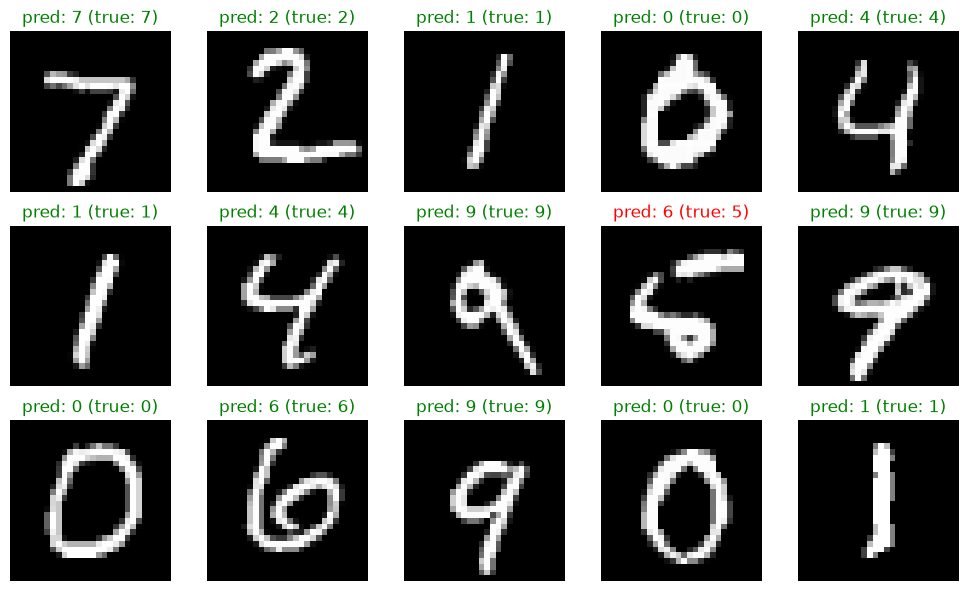

In [15]:
import matplotlib.pyplot as plt

# предсказания на первых 15 тестовых картинках
preds = model.predict(x_test[:15])
pred_labels = preds.argmax(axis=1)

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    correct = pred_labels[i] == y_test[i]
    ax.set_title(
        f"pred: {pred_labels[i]} (true: {y_test[i]})",
        color="green" if correct else "red",
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 251us/step


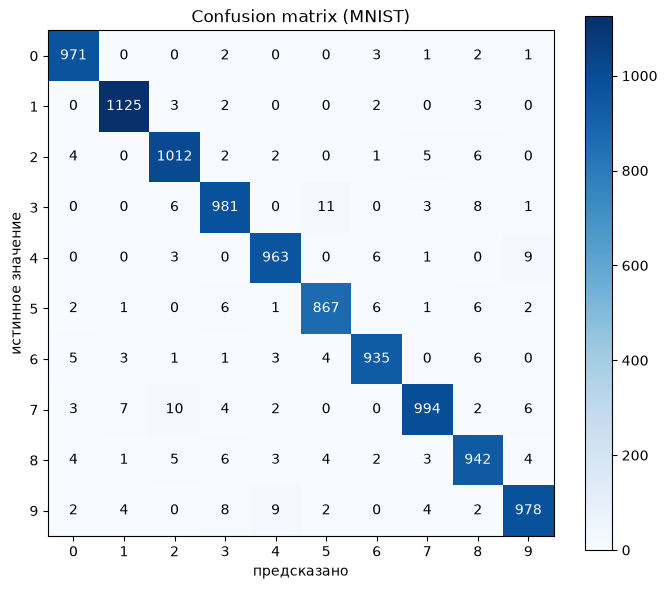

In [16]:
# confusion matrix: какие цифры модель чаще всего путает
all_preds = model.predict(x_test).argmax(axis=1)

confusion = np.zeros((10, 10), dtype=int)
for true, pred in zip(y_test, all_preds):
    confusion[true, pred] += 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("предсказано")
ax.set_ylabel("истинное значение")
ax.set_title("Confusion matrix (MNIST)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, confusion[i, j], ha="center", va="center",
                 color="white" if confusion[i, j] > confusion.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()